# Lab 2 (Parcial 2) · Parte I — Predicción del origen de nombres con una RNN

## Objetivo

Clasificar **apellidos** según su idioma de origen leyendo el nombre **carácter a carácter** con una red neuronal recurrente (RNN). Es aprendizaje supervisado: la entrada es una secuencia de longitud variable (el nombre) y la salida es **una única clase** (el idioma). Es un problema *muchos a uno*: la red lee todo el nombre y solo al final emite una predicción.

Tareas de la guía (Parte I):

1. Analizar el código proporcionado (`Lab2_RNN_PredictingNames.ipynb`): cómo se codifican los datos de entrada, cómo funciona la RNN y cuál es el papel del **estado oculto**.
2. Ejecutar el modelo, evaluarlo con las métricas proporcionadas y **proponer mejoras** (rendimiento, velocidad, calidad del código). Analizar el efecto de los hiperparámetros: **longitud de la secuencia de entrada, tamaño de la capa oculta, número de épocas y tasa de aprendizaje**.
3. Analizar la **matriz de confusión**: qué países se confunden más y por qué.
4. Implementar una **red feedforward (FNN)** con parámetros similares y compararla con la RNN.
5. Redactar **conclusiones** basadas en los experimentos.

> **Nota sobre el número de clases.** La guía y las diapositivas hablan de 18 países (el tutorial original de PyTorch usa 18 idiomas), pero el archivo `names.zip` del campus virtual contiene **14 idiomas**: Arabic, Chinese, Czech, Dutch, English, French, German, Greek, Irish, Italian, Japanese, Polish, Russian y Spanish. Todo el cuaderno trabaja con esos 14.

## 0. Preparación del entorno

En Colab basta con subir `names.zip` y descomprimirlo; en local se usa el entorno de `Parcial-2/requirements.txt` (incluye `scikit-learn` para las métricas). La celda localiza la carpeta del lab y, si hace falta, descomprime `names.zip` en `data/names`.

Se trabaja en **CPU**: el modelo es muy pequeño (≈ 26 000 parámetros) y el código base procesa los nombres de uno en uno, así que una GPU no aportaría nada (el coste lo domina el bucle de Python, no el cálculo).

In [1]:
%matplotlib inline
import collections
import copy
import glob
import json
import os
import random
import string
import time
import unicodedata
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import sklearn.metrics
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

LAB_DIR = None
for candidato in (Path.cwd(), Path.cwd() / 'Lab-2',
                  Path.cwd() / 'Parcial-2' / 'Lab-2-Recurrent-Neural-Networks' / 'Lab-2'):
    if (candidato / 'names.zip').exists() or (candidato / 'data').exists():
        LAB_DIR = candidato
        break
if LAB_DIR is None:
    raise FileNotFoundError('No se encuentra la carpeta del Lab 2 (con names.zip o data/)')

DIR_NOMBRES = LAB_DIR / 'data' / 'names'
if not DIR_NOMBRES.exists():
    with zipfile.ZipFile(LAB_DIR / 'names.zip') as z:
        z.extractall(LAB_DIR / 'data', members=[m for m in z.namelist()
                                               if m.startswith('names/') and m.endswith('.txt')])

device = torch.device('cpu')
torch.set_default_device(device)
torch.set_num_threads(min(4, os.cpu_count()))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.precision', 4)
print('PyTorch', torch.__version__, '| dispositivo', device, '|', len(list(DIR_NOMBRES.glob('*.txt'))), 'idiomas')

PyTorch 2.15.0 | dispositivo cpu | 14 idiomas


# 1. El código base, explicado

## 1.1. Codificación de los caracteres

El vocabulario son **58 caracteres**: las 52 letras ASCII (minúsculas y mayúsculas), cinco signos (`" .,;'"`) y `_`, que hace de **token desconocido** (`<unk>`): cualquier carácter que no esté en la lista se codifica como `_`.

`unicodeToAscii` normaliza el texto en forma **NFD** (descompone «à» en «a» + acento combinante) y elimina los caracteres de categoría `Mn` (marcas diacríticas). Así «Ślusàrski» pasa a «Slusarski» y el vocabulario no necesita una entrada para cada letra acentuada.

In [2]:
# Usamos "_" para representar un carácter fuera de vocabulario (OOV)
allowed_characters = string.ascii_letters + " .,;'" + "_"
n_letters = len(allowed_characters)
print(n_letters)

# Unicode -> ASCII: descompone (NFD) y quita las marcas diacríticas (categoría Mn)
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
        and c in allowed_characters
    )

print(f"converting 'Ślusàrski' to {unicodeToAscii('Ślusàrski')}")

58
converting 'Ślusàrski' to Slusarski


Cada carácter se representa con un vector **one-hot** de tamaño 58: todo ceros salvo un 1 en la posición del carácter (`'a'` → posición 0, `'A'` → posición 26). Un nombre de longitud $T$ se convierte en un tensor de forma **`(T, 1, 58)`**: una fila por carácter (el eje temporal), un 1 en medio porque `nn.RNN` espera un eje de lote (*batch*) y aquí el lote es de un solo nombre, y 58 columnas del one-hot.

In [3]:
# Índice de una letra en allowed_characters ("a" = 0); los caracteres desconocidos van a "_"
def letterToIndex(letter):
    if letter not in allowed_characters:
        return allowed_characters.find("_")
    else:
        return allowed_characters.find(letter)

# Nombre -> tensor <longitud x 1 x n_letters> de vectores one-hot
def lineToTensor(line):
    tensor = torch.zeros(len(line), 1, n_letters)
    for li, letter in enumerate(line):
        tensor[li][0][letterToIndex(letter)] = 1
    return tensor

t = lineToTensor('Ahn')
print('forma de lineToTensor("Ahn"):', tuple(t.shape))
print('posición del 1 en cada paso:', t.argmax(dim=2).flatten().tolist(),
      '->', [allowed_characters[i] for i in t.argmax(dim=2).flatten()])

forma de lineToTensor("Ahn"): (3, 1, 58)
posición del 1 en cada paso: [26, 7, 13] -> ['A', 'h', 'n']


## 1.2. El conjunto de datos

`NamesDataset` lee cada `Idioma.txt` (un apellido por línea), guarda el nombre, su tensor one-hot y la etiqueta (el nombre del archivo). La etiqueta numérica es la posición del idioma en `labels_uniq`. Implementa `__len__` y `__getitem__`, así que se puede usar como un `Dataset` de PyTorch.

**Dos cambios mínimos respecto al original**, ambos de reproducibilidad: el original construye `labels_uniq = list(labels_set)`, y el orden de un `set` de cadenas **cambia en cada ejecución de Python** (aleatorización del *hash*), así que el índice de cada idioma, la matriz de confusión y la partición dependían de la sesión. Aquí se ordena (`sorted`), igual que la lista de archivos.

In [4]:
class NamesDataset(torch.utils.data.Dataset):

    def __init__(self, data_dir):
        self.data_dir = data_dir           # procedencia del conjunto de datos
        self.load_time = time.localtime
        labels_set = set()                 # conjunto de clases

        self.data = []
        self.data_tensors = []
        self.labels = []
        self.labels_tensors = []

        # leer todos los .txt del directorio (ordenados: cambio para que sea reproducible)
        text_files = sorted(glob.glob(os.path.join(data_dir, '*.txt')))
        for filename in text_files:
            label = os.path.splitext(os.path.basename(filename))[0]
            labels_set.add(label)
            lines = open(filename, encoding='utf-8').read().strip().split('\n')
            for name in lines:
                self.data.append(name)
                self.data_tensors.append(lineToTensor(name))
                self.labels.append(label)

        # tensores de las etiquetas (orden alfabético: cambio para que sea reproducible)
        self.labels_uniq = sorted(labels_set)
        for idx in range(len(self.labels)):
            temp_tensor = torch.tensor([self.labels_uniq.index(self.labels[idx])], dtype=torch.long)
            self.labels_tensors.append(temp_tensor)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        data_item = self.data[idx]
        data_label = self.labels[idx]
        data_tensor = self.data_tensors[idx]
        label_tensor = self.labels_tensors[idx]
        return label_tensor, data_tensor, data_label, data_item


alldata = NamesDataset(str(DIR_NOMBRES))
clases = alldata.labels_uniq
print(f'loaded {len(alldata)} items of data, {len(clases)} clases')
print(f'example = {alldata[0][2]!r}, {alldata[0][3]!r}, tensor {tuple(alldata[0][1].shape)}')

loaded 19733 items of data, 14 clases
example = 'Arabic', 'Khoury', tensor (6, 1, 58)


### Cómo son los datos

Antes de entrenar conviene mirar la distribución de clases y las longitudes, porque condicionan qué significa un «buen» resultado.

,nombres,distintos,% del total
Russian,9408,9342,47.6765
English,3668,3668,18.5882
Arabic,2000,108,10.1353
Japanese,991,990,5.0220
German,724,706,3.6690
Italian,709,701,3.5930
Czech,519,503,2.6301
Spanish,298,296,1.5102
Dutch,297,286,1.5051
French,277,273,1.4037


Longitud de los nombres: media 7.2, mediana 7, percentil 99 13, máximo 20
Clasificador trivial (siempre "Russian"): exactitud = 0.4768


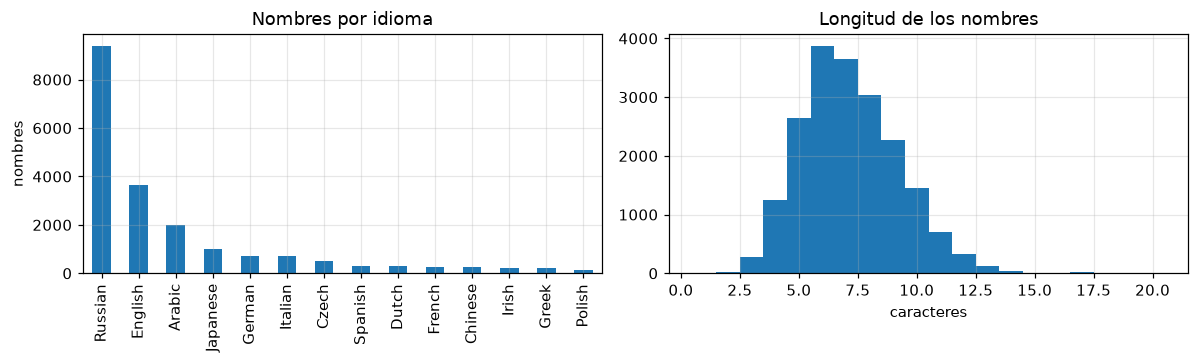

In [5]:
conteo = pd.Series(alldata.labels).value_counts()
unicos = pd.Series(alldata.data).groupby(pd.Series(alldata.labels)).nunique()
tabla_clases = pd.DataFrame({'nombres': conteo, 'distintos': unicos.reindex(conteo.index),
                             '% del total': 100 * conteo / conteo.sum()})
display(tabla_clases)

longitudes = np.array([len(n) for n in alldata.data])
print(f'Longitud de los nombres: media {longitudes.mean():.1f}, mediana {np.median(longitudes):.0f}, '
      f'percentil 99 {np.percentile(longitudes, 99):.0f}, máximo {longitudes.max()}')
print(f'Clasificador trivial (siempre "Russian"): exactitud = {conteo.max() / conteo.sum():.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
conteo.plot.bar(ax=ax[0], color='tab:blue')
ax[0].set_title('Nombres por idioma'); ax[0].set_ylabel('nombres')
ax[1].hist(longitudes, bins=np.arange(1, 22) - 0.5, color='tab:blue')
ax[1].set_title('Longitud de los nombres'); ax[1].set_xlabel('caracteres')
plt.tight_layout(); plt.show()

Tres hechos que condicionan todo el análisis:

* **Desequilibrio fuerte**: *Russian* es casi la mitad de los datos y *English* casi una quinta parte; *Polish* tiene 139 nombres. Un clasificador que siempre diga «Russian» ya acierta el 47,7 %. Por eso además de la exactitud miramos el **F1 ponderado** (proporcionado en el código) y el **F1 macro** (media simple por clase: cada idioma pesa igual).
* **Duplicados**: *Arabic* tiene 2000 líneas pero solo **108 nombres distintos**. Casi todos los árabes del test aparecerán también en entrenamiento, así que la red los puede **memorizar**.
* **Nombres cortos**: la mediana es de 7 caracteres y el máximo 20, así que las secuencias son cortas para una RNN (no hay problemas serios de gradiente que se desvanece).

## 1.3. Partición entrenamiento / prueba

`random_split` reparte el 85 % para entrenamiento y el 15 % para prueba con una semilla fija (2024). El código original llama al conjunto de prueba «validation» en el mensaje, pero solo hay dos conjuntos: no hay validación para elegir hiperparámetros (lo arreglamos en el apartado 2).

In [6]:
train_set, test_set = torch.utils.data.random_split(
    alldata, [.85, .15], generator=torch.Generator(device=device).manual_seed(2024))
print(f'train examples = {len(train_set)}, test examples = {len(test_set)}')

train examples = 16774, test examples = 2959


## 1.4. La red recurrente

`CharRNN` tiene tres piezas:

1. **`nn.RNN(58, 128)`**: la capa recurrente. En cada paso $t$ recibe el one-hot del carácter $\mathbf{x}_t$ y el estado anterior $\mathbf{h}_{t-1}$ y calcula

   $$\mathbf{h}_t = \tanh\left(\mathbf{x}_t \mathbf{W}_{xh} + \mathbf{h}_{t-1}\mathbf{W}_{hh} + \mathbf{b}_h\right),\qquad \mathbf{h}_0=\mathbf{0}.$$

   Son exactamente las ecuaciones de la teoría: $\mathbf{W}_{xh}\in\mathbb{R}^{58\times128}$ (entrada → oculta), $\mathbf{W}_{hh}\in\mathbb{R}^{128\times128}$ (oculta → oculta) y la activación por defecto es la **tangente hiperbólica**. Las mismas matrices se usan en **todos los pasos** (pesos compartidos), por eso la red acepta nombres de cualquier longitud.
2. **`h2o = nn.Linear(128, 14)`**: la capa de salida, $\mathbf{o} = \mathbf{h}_T\mathbf{W}_{hq} + \mathbf{b}_q$, que convierte el **último estado oculto** en 14 puntuaciones (*logits*), una por idioma.
3. **`LogSoftmax`**: convierte los logits en log-probabilidades. Junto con `NLLLoss` en el entrenamiento equivale a la **entropía cruzada** con softmax.

`self.rnn(line_tensor)` devuelve `rnn_out` (el estado oculto en **todos** los pasos, forma `(T, 1, 128)`) y `hidden` (solo el **último**, forma `(1, 1, 128)`). La clasificación usa `hidden[0]`, el estado tras leer el nombre entero: es un problema *muchos a uno*.

### El papel del estado oculto

El estado oculto $\mathbf{h}_t$ es la **memoria** de la red: un vector de 128 números que resume todo lo leído hasta el paso $t$. Cada carácter nuevo lo actualiza combinando lo que ya había (vía $\mathbf{W}_{hh}$) con el carácter actual (vía $\mathbf{W}_{xh}$). Al final, $\mathbf{h}_T$ es una **representación de longitud fija de un nombre de longitud variable**, y la capa de salida solo tiene que leerla. Sin él, la red no podría relacionar un carácter con los anteriores (por ejemplo, saber que la «v» de «-ov» va detrás de una «o» al final del nombre).

In [7]:
class CharRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(CharRNN, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size)
        self.h2o = nn.Linear(hidden_size, output_size)
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, line_tensor):
        rnn_out, hidden = self.rnn(line_tensor)   # rnn_out: (T, 1, H) ; hidden: (1, 1, H)
        output = self.h2o(hidden[0])              # último estado oculto -> 14 puntuaciones
        output = self.softmax(output)             # log-probabilidades
        return output


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())


n_hidden = 128
torch.manual_seed(0)
rnn = CharRNN(n_letters, n_hidden, len(clases))
print(rnn)
for nombre, p in rnn.named_parameters():
    print(f'  {nombre:15s} {tuple(p.shape)}')
print('parámetros:', contar_parametros(rnn))

CharRNN(
  (rnn): RNN(58, 128)
  (h2o): Linear(in_features=128, out_features=14, bias=True)
  (softmax): LogSoftmax(dim=1)
)
  rnn.weight_ih_l0 (128, 58)
  rnn.weight_hh_l0 (128, 128)
  rnn.bias_ih_l0  (128,)
  rnn.bias_hh_l0  (128,)
  h2o.weight      (14, 128)
  h2o.bias        (14,)
parámetros: 25870


`nn.RNN` guarda las matrices **transpuestas** respecto a la notación de la teoría (`weight_ih_l0` es $128\times58$, es decir $\mathbf{W}_{xh}^\top$) y tiene **dos** sesgos (`bias_ih` y `bias_hh`), que se suman y equivalen a un único $\mathbf{b}_h$. Total: $58\cdot128 + 128\cdot128 + 2\cdot128 + 128\cdot14 + 14 = 25\,870$ parámetros.

La predicción es la clase con mayor log-probabilidad (`topk(1)`). Sin entrenar, las 14 salidas valen ≈ $\log(1/14) = -2{,}64$: la red reparte la probabilidad casi por igual.

In [8]:
def label_from_output(output, output_labels):
    top_n, top_i = output.topk(1)
    label_i = top_i[0].item()
    return output_labels[label_i], label_i

output = rnn(lineToTensor('Albert'))
print(output)
print(label_from_output(output, clases), '| log(1/14) =', round(np.log(1 / 14), 3))

tensor([[-2.6010, -2.6652, -2.7040, -2.6133, -2.6604, -2.5792, -2.7221, -2.5736,
         -2.6394, -2.7533, -2.6098, -2.6604, -2.5658, -2.6202]],
       grad_fn=<LogSoftmaxBackward0>)
('Russian', 12) | log(1/14) = -2.639


## 1.5. Entrenamiento (función original)

`train()` hace descenso por gradiente estocástico (**SGD**, tasa 0,05) por minilotes de 64 nombres. Como los nombres tienen longitudes distintas, el código **no** apila un lote en un único tensor: recorre los 64 nombres **uno a uno**, suma sus 64 pérdidas y hace un único `backward()` por lote. Después **recorta el gradiente** a norma 3 (*gradient clipping*, visto en teoría) y actualiza los pesos.

Dos detalles importantes para las mejoras:

* La pérdida del lote es la **suma** (no la media) de 64 pérdidas, así que la tasa efectiva es 64 veces mayor que la nominal; el recorte a norma 3 es lo que evita que esos pasos sean enormes.
* Procesar los nombres de uno en uno es **muy lento**: 16 774 llamadas a la red por época, cada una con un solo nombre.

In [9]:
def train(rnn, training_data, n_epoch=30, n_batch_size=64, report_every=5, learning_rate=0.05,
          criterion=nn.NLLLoss()):
    """Entrena con minilotes (bucle nombre a nombre dentro de cada lote)."""
    current_loss = 0
    all_losses = []
    rnn.train()
    optimizer = torch.optim.SGD(rnn.parameters(), lr=learning_rate)
    print(f"training on data set with n = {len(training_data)}")

    for iter in range(1, n_epoch + 1):
        rnn.zero_grad()
        # minilotes: no se pueden usar DataLoaders porque cada nombre tiene una longitud distinta
        batches = list(range(len(training_data)))
        random.shuffle(batches)
        batches = np.array_split(batches, len(batches) // n_batch_size)

        for idx, batch in enumerate(batches):
            batch_loss = 0
            for i in batch:                          # cada ejemplo del lote, de uno en uno
                (label_tensor, text_tensor, label, text) = training_data[i]
                output = rnn.forward(text_tensor)
                loss = criterion(output, label_tensor)
                batch_loss += loss                   # suma (no media) de las pérdidas
            batch_loss.backward()                    # BPTT a través de cada nombre
            nn.utils.clip_grad_norm_(rnn.parameters(), 3)
            optimizer.step()
            optimizer.zero_grad()
            current_loss += batch_loss.item() / len(batch)

        all_losses.append(current_loss / len(batches))
        if iter % report_every == 0:
            print(f"{iter} ({iter / n_epoch:.0%}): \t average batch loss = {all_losses[-1]}")
        current_loss = 0

    return all_losses

# 2. Ejecución del modelo base, evaluación y mejoras

## 2.1. Modelo base

Se entrena exactamente con los parámetros por defecto (30 épocas, tasa 0,05, lotes de 64, 128 neuronas ocultas), fijando las semillas para que el resultado sea reproducible.

training on data set with n = 16774


5 (17%): 	 average batch loss = 0.8963942470423838


10 (33%): 	 average batch loss = 0.7442887681113645


15 (50%): 	 average batch loss = 0.652398010120627


20 (67%): 	 average batch loss = 0.5748439996192123


25 (83%): 	 average batch loss = 0.5119699645623417


30 (100%): 	 average batch loss = 0.4581267925636669
training took 98.0s  (3.27 s por época)


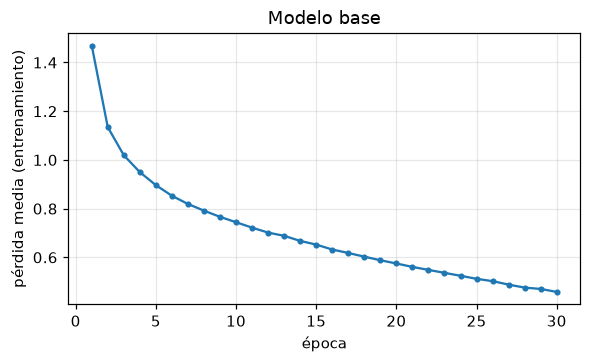

In [10]:
random.seed(0); np.random.seed(0); torch.manual_seed(0)
rnn = CharRNN(n_letters, n_hidden, len(clases))
inicio = time.time()
all_losses = train(rnn, train_set, n_epoch=30, learning_rate=0.05, report_every=5)
t_base = time.time() - inicio
print(f'training took {t_base:.1f}s  ({t_base / len(all_losses):.2f} s por época)')

plt.figure(figsize=(6, 3.2))
plt.plot(range(1, len(all_losses) + 1), all_losses, marker='.')
plt.xlabel('época'); plt.ylabel('pérdida media (entrenamiento)'); plt.title('Modelo base')
plt.show()

La función `evaluate` del código original pasa cada nombre de prueba por la red, construye la **matriz de confusión** normalizada por filas (fila = idioma real, columna = predicho; cada fila suma 1) y calcula la exactitud y el F1 ponderado con `scikit-learn`. La mantenemos tal cual (añadiendo que devuelva las métricas) y le sumamos el **F1 macro**.

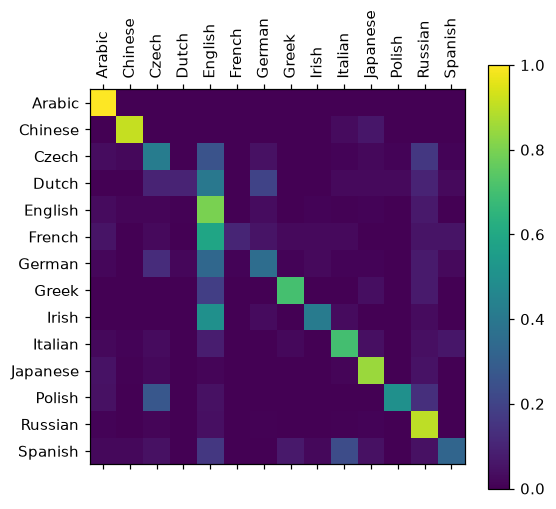

Accuracy: 0.8043 | F1 (weighted): 0.7959 | F1 (macro): 0.5752


In [11]:
def evaluate(rnn, testing_data, classes, dibujar=True):
    confusion = torch.zeros(len(classes), len(classes))
    all_true_labels, all_predictions = [], []
    rnn.eval()
    with torch.no_grad():
        for i in range(len(testing_data)):
            (label_tensor, text_tensor, label, text) = testing_data[i]
            output = rnn(text_tensor)
            guess, guess_i = label_from_output(output, classes)
            label_i = classes.index(label)
            confusion[label_i][guess_i] += 1
            all_true_labels.append(label_i)
            all_predictions.append(guess_i)

    for i in range(len(classes)):                    # normalizar cada fila
        denom = confusion[i].sum()
        if denom > 0:
            confusion[i] = confusion[i] / denom

    if dibujar:
        fig = plt.figure(figsize=(5.5, 5))
        ax = fig.add_subplot(111)
        cax = ax.matshow(confusion.cpu().numpy())
        fig.colorbar(cax)
        ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
        ax.set_yticks(np.arange(len(classes)), labels=classes)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
        ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
        ax.grid(False)
        plt.show()

    res = {'accuracy': sklearn.metrics.accuracy_score(all_true_labels, all_predictions),
           'f1_weighted': sklearn.metrics.f1_score(all_true_labels, all_predictions, average='weighted'),
           'f1_macro': sklearn.metrics.f1_score(all_true_labels, all_predictions, average='macro')}
    print(f"Accuracy: {res['accuracy']:.4f} | F1 (weighted): {res['f1_weighted']:.4f} | F1 (macro): {res['f1_macro']:.4f}")
    return res


res_base = evaluate(rnn, test_set, clases)

Con los parámetros por defecto (30 épocas) el modelo base acierta el **80,4 %** del test, muy por encima del clasificador trivial (47,7 %). La pérdida de entrenamiento sigue bajando en la época 30 (0,46), así que todavía no ha convergido. Pero el **F1 macro (0,58)** es mucho más bajo que la exactitud: los idiomas grandes (Russian, English, Arabic, Japanese) se reconocen bien y los pequeños mucho peor. En la matriz, la diagonal es brillante en las clases grandes y apagada en Dutch, French, Spanish, Czech o Irish, cuyas filas se van a la columna de English.

### El estado oculto en acción

Para ver qué hace el estado oculto, se clasifica cada **prefijo** del nombre: la predicción tras leer $t$ caracteres es la que haría la red si el nombre acabara ahí, y depende únicamente de $\mathbf{h}_t$. La creencia de la red cambia según llegan caracteres reveladores.

In [12]:
def prediccion_por_prefijo(modelo, nombre, k=2):
    filas = []
    with torch.no_grad():
        for t in range(1, len(nombre) + 1):
            logp = modelo(lineToTensor(nombre[:t]))[0]
            p, i = logp.exp().topk(k)
            filas.append({'prefijo': nombre[:t]} | {f'top{j + 1}': f'{clases[i[j]]} ({p[j]:.2f})' for j in range(k)})
    return pd.DataFrame(filas).set_index('prefijo')

rnn.eval()
for nombre in ['Nakamura', 'Ivanov', 'Schmidt']:
    display(prediccion_por_prefijo(rnn, nombre))

,top1,top2
prefijo,,
N,Russian (0.59),English (0.09)
Na,Japanese (0.44),Russian (0.15)
Nak,Chinese (0.74),Polish (0.10)
Naka,Japanese (0.94),Russian (0.02)
Nakam,Arabic (0.56),Russian (0.16)
Nakamu,Arabic (0.53),Japanese (0.47)
Nakamur,Russian (0.92),Japanese (0.03)
Nakamura,Japanese (0.99),Arabic (0.01)


,top1,top2
prefijo,,
I,Russian (0.50),Chinese (0.09)
Iv,Russian (1.00),Czech (0.00)
Iva,Arabic (0.67),Czech (0.20)
Ivan,English (0.67),Chinese (0.11)
Ivano,Italian (0.83),Russian (0.09)
Ivanov,Russian (1.00),Czech (0.00)


,top1,top2
prefijo,,
S,Russian (0.30),Chinese (0.09)
Sc,Russian (0.31),Polish (0.23)
Sch,German (0.38),Russian (0.20)
Schm,German (0.83),English (0.07)
Schmi,Italian (0.84),Polish (0.09)
Schmid,English (0.35),Czech (0.28)
Schmidt,English (0.60),German (0.24)


Se ve cómo la información se acumula en el estado oculto:

* Con una sola letra la red apuesta por la clase mayoritaria (Russian), que es lo más probable sin más información.
* «Naka» ya es japonés con un 94 %, y «Ivanov» es ruso con un 100 % justo al llegar la «v» final de «-ov».
* Las predicciones de los prefijos intermedios son erráticas («Nakamu» → Arabic, «Ivano» → Italian, «Schmi» → Italian). Es lógico: la red **solo se ha entrenado con nombres completos**, así que un prefijo es una entrada que nunca ha visto como nombre terminado. Lo que importa es el estado final.
* «Schmidt» acaba clasificado como **English** (60 %) frente a German (24 %): un ejemplo de la confusión German → English que se analiza en el apartado 3.

El estado oculto es, por tanto, un resumen que se actualiza carácter a carácter y en el que el final del nombre pesa mucho: es lo último que ha entrado.

## 2.2. Problemas detectados en el código base

1. **`unicodeToAscii` se define pero nunca se usa.** `NamesDataset` pasa el nombre en bruto a `lineToTensor`, y las letras acentuadas (é, ö, ß, ñ…) se codifican como `_`: «Ślusàrski» se convierte en «_lus_rski». Se pierde información justo en los idiomas con más diacríticos (Czech, Polish, German, Spanish, French).
2. **Lentitud.** Los nombres se pasan de uno en uno por la red: ≈ 16 800 llamadas por época.
3. **Sin conjunto de validación.** No hay forma honesta de elegir hiperparámetros ni el número de épocas (si se eligen mirando el test, el resultado del test deja de ser una estimación fiable).
4. **Pérdida sumada en el lote**: la tasa de aprendizaje efectiva depende del tamaño del lote.
5. **Etiquetas no reproducibles** (`list(set)`), ya corregido arriba.

In [13]:
afectados = [n for n in alldata.data if any(c not in allowed_characters for c in n)]
raros = collections.Counter(c for n in afectados for c in n if c not in allowed_characters)
print(f'{len(afectados)} nombres contienen caracteres fuera del vocabulario; los más comunes:', raros.most_common(8))
for n in afectados[:5]:
    print(f'  {n!r:16} -> en el código base: {"".join(c if c in allowed_characters else "_" for c in n)!r:16}'
          f'  con unicodeToAscii: {unicodeToAscii(n)!r}')

180 nombres contienen caracteres fuera del vocabulario; los más comunes: [('-', 25), ('ö', 24), ('é', 21), ('í', 14), ('ä', 13), ('ó', 13), ('á', 12), ('ü', 11)]
  'Au-Yong'        -> en el código base: 'Au_Yong'         con unicodeToAscii: 'AuYong'
  'Ou-Yang'        -> en el código base: 'Ou_Yang'         con unicodeToAscii: 'OuYang'
  'Ow-Yang'        -> en el código base: 'Ow_Yang'         con unicodeToAscii: 'OwYang'
  'Lu:'            -> en el código base: 'Lu_'             con unicodeToAscii: 'Lu'
  'Maxa/B'         -> en el código base: 'Maxa_B'          con unicodeToAscii: 'MaxaB'


## 2.3. Versión mejorada

**Mejoras de código y velocidad**

* Se aplica `unicodeToAscii` antes de codificar (los caracteres que siguen fuera del vocabulario, como el guion, se eliminan igual que hace esa función).
* Los nombres se guardan como **índices** (no como one-hot) y el one-hot se construye por lotes con `F.one_hot`.
* **Procesamiento por lotes con `pack_padded_sequence`**: los 64 nombres de un lote se rellenan (*padding*) hasta la longitud del más largo y se «empaquetan» indicando la longitud real de cada uno. `nn.RNN` procesa entonces el lote entero en paralelo **sin leer el relleno**, y `h_n` contiene el último estado **real** de cada nombre. El resultado es matemáticamente el mismo que ir uno a uno, pero con una sola llamada por lote.
* La pérdida es la **media** del lote (`cross_entropy` sobre logits, que ya incluye el softmax).

**Mejoras de metodología y rendimiento**

* El 85 % de entrenamiento se divide en **entrenamiento (≈ 72 %)** y **validación (≈ 13 %)**. El **test es el mismo** que el del modelo base, así que los resultados son comparables.
* **Adam** en lugar de SGD y **parada temprana** (*early stopping*): se vigila la pérdida de validación, se guarda el mejor modelo y se para tras `paciencia` épocas sin mejorar (teoría: «Use training, validation and test sets with an early stopping scheme and a patience value»).

In [14]:
PAD = n_letters   # índice de relleno (fuera del one-hot)

def codificar(nombre, ascii=True):
    s = unicodeToAscii(nombre) if ascii else nombre
    return torch.tensor([letterToIndex(c) for c in s] or [letterToIndex('_')])

y_todos = np.array([clases.index(l) for l in alldata.labels])
X_ascii = [codificar(n) for n in alldata.data]
X_bruto = [codificar(n, ascii=False) for n in alldata.data]

# mismo test que el modelo base; el entrenamiento original se divide en entrenamiento + validación
idx_test = np.array(test_set.indices)
perm = torch.randperm(len(train_set), generator=torch.Generator().manual_seed(2025)).numpy()
n_val = round(0.15 * len(train_set))
idx_val = np.array(train_set.indices)[perm[:n_val]]
idx_train = np.array(train_set.indices)[perm[n_val:]]
print(f'entrenamiento {len(idx_train)} | validación {len(idx_val)} | test {len(idx_test)}')


def hacer_lote(X, ids, max_len=None, desde='inicio'):
    """Rellena un lote de nombres. max_len recorta cada nombre a sus primeros (o últimos) caracteres."""
    seqs = [X[i] for i in ids]
    if max_len is not None:
        seqs = [s[:max_len] if desde == 'inicio' else s[-max_len:] for s in seqs]
    longitudes = torch.tensor([len(s) for s in seqs])
    return pad_sequence(seqs, batch_first=True, padding_value=PAD), longitudes


class CharRNNLotes(nn.Module):
    """Misma arquitectura que CharRNN, pero procesa un lote completo de nombres de distinta longitud."""
    def __init__(self, n_entrada, n_oculta, n_clases):
        super().__init__()
        self.n_entrada = n_entrada
        self.rnn = nn.RNN(n_entrada, n_oculta, batch_first=True)
        self.h2o = nn.Linear(n_oculta, n_clases)

    def forward(self, x, longitudes):
        x = F.one_hot(x, self.n_entrada + 1)[..., :self.n_entrada].float()    # (B, T, 58); el relleno queda a 0
        x = pack_padded_sequence(x, longitudes, batch_first=True, enforce_sorted=False)
        _, h = self.rnn(x)                    # h: (1, B, H) = último estado REAL de cada nombre
        return self.h2o(h[-1])                # logits (B, C)

entrenamiento 14258 | validación 2516 | test 2959


In [15]:
def predecir(modelo, X, ids, max_len=None, desde='inicio', bs=4096):
    modelo.eval()
    with torch.no_grad():
        logits = torch.cat([modelo(*hacer_lote(X, ids[i:i + bs], max_len, desde)) for i in range(0, len(ids), bs)])
    modelo.train()
    return logits


def metricas(modelo, X, ids, max_len=None, desde='inicio'):
    logits = predecir(modelo, X, ids, max_len, desde)
    y = torch.as_tensor(y_todos[ids])
    pred = logits.argmax(1).numpy()
    return {'loss': F.cross_entropy(logits, y).item(),
            'accuracy': sklearn.metrics.accuracy_score(y_todos[ids], pred),
            'f1_weighted': sklearn.metrics.f1_score(y_todos[ids], pred, average='weighted'),
            'f1_macro': sklearn.metrics.f1_score(y_todos[ids], pred, average='macro')}, pred


def entrenar(crear_modelo, X=X_ascii, lr=1e-3, epocas=40, paciencia=5, bs=64, semilla=0,
             max_len=None, desde='inicio', optimizador='adam', perdida='media', clip=3.0, pesos_clase=None,
             ids=None, ultimo=False):
    """Entrena con minilotes y parada temprana sobre la pérdida de validación.
    Devuelve el mejor modelo (según validación; con ultimo=True, el de la última época) y la historia."""
    ids_ent = idx_train if ids is None else ids
    torch.manual_seed(semilla); rng = np.random.default_rng(semilla)
    modelo = crear_modelo()
    opt = (torch.optim.Adam if optimizador == 'adam' else torch.optim.SGD)(modelo.parameters(), lr=lr)
    reduccion = 'sum' if perdida == 'suma' else 'mean'
    w = None if pesos_clase is None else torch.as_tensor(pesos_clase, dtype=torch.float32)
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    mejor, mejor_estado, sin_mejora, inicio = np.inf, None, 0, time.time()
    for epoca in range(epocas):
        orden = rng.permutation(ids_ent)
        perdida_ac, aciertos = 0.0, 0
        for i in range(0, len(orden), bs):
            ids = orden[i:i + bs]
            x, L = hacer_lote(X, ids, max_len, desde)
            y = torch.as_tensor(y_todos[ids])
            logits = modelo(x, L)
            loss = F.cross_entropy(logits, y, weight=w, reduction=reduccion)
            opt.zero_grad(); loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(modelo.parameters(), clip)
            opt.step()
            perdida_ac += loss.item() * (1 if reduccion == 'sum' else len(ids))
            aciertos += (logits.argmax(1) == y).sum().item()
        val, _ = metricas(modelo, X, idx_val, max_len, desde)
        hist['train_loss'].append(perdida_ac / len(orden)); hist['train_acc'].append(aciertos / len(orden))
        hist['val_loss'].append(val['loss']); hist['val_acc'].append(val['accuracy'])
        if val['loss'] < mejor:
            mejor, mejor_estado, sin_mejora = val['loss'], copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if paciencia and sin_mejora >= paciencia:
                break
    if not ultimo:
        modelo.load_state_dict(mejor_estado)
    mejor_ep = int(np.argmin(hist['val_loss'])) + 1
    return modelo, {'hist': hist, 'mejor_epoca': mejor_ep, 'epocas': len(hist['val_loss']),
                    'segundos': time.time() - inicio, 'val_loss': hist['val_loss'][mejor_ep - 1],
                    'val_acc': hist['val_acc'][mejor_ep - 1]}

### Paso a paso: del código base a la versión mejorada

Se mide el efecto de cada cambio por separado sobre el **mismo test**:

* **A · Base**: el modelo de 2.1.
* **B · Lotes empaquetados**: misma optimización que el base (SGD 0,05, pérdida sumada, recorte a 3, 30 épocas, sin validación), pero procesando por lotes. Debe dar un resultado parecido en mucho menos tiempo.
* **C · + `unicodeToAscii`**: igual que B, aplicando la conversión a ASCII.
* **D · + Adam, pérdida media y parada temprana**: la versión mejorada (con los hiperparámetros por defecto de este cuaderno; se ajustan en 2.4).

In [16]:
def nueva_rnn(h=128):
    return lambda: CharRNNLotes(n_letters, h, len(clases))

pasos = {}
pasos['A · Base (nombre a nombre)'] = res_base | {'segundos/época': t_base / len(all_losses)}

for nombre, X in [('B · Lotes empaquetados', X_bruto), ('C · + unicodeToAscii', X_ascii)]:
    # misma optimización que el original: todo el 85 %, SGD 0,05 con pérdida sumada, 30 épocas,
    # sin validación ni parada temprana (se usa el modelo de la última época)
    m, info = entrenar(nueva_rnn(), X=X, lr=0.05, epocas=30, paciencia=None, optimizador='sgd',
                       perdida='suma', ids=np.array(train_set.indices), ultimo=True)
    res, _ = metricas(m, X, idx_test)
    pasos[nombre] = res | {'segundos/época': info['segundos'] / info['epocas']}

modelo_d, info_d = entrenar(nueva_rnn())
res_d, _ = metricas(modelo_d, X_ascii, idx_test)
pasos['D · + Adam, media, parada temprana'] = res_d | {'segundos/época': info_d['segundos'] / info_d['epocas']}
print(f"D: mejor época {info_d['mejor_epoca']} de {info_d['epocas']}")

tabla_pasos = pd.DataFrame(pasos).T[['accuracy', 'f1_weighted', 'f1_macro', 'segundos/época']]
display(tabla_pasos)

D: mejor época 23 de 28


,accuracy,f1_weighted,f1_macro,segundos/época
A · Base (nombre a nombre),0.8043,0.7959,0.5752,3.2674
B · Lotes empaquetados,0.7996,0.7883,0.5581,0.3969
C · + unicodeToAscii,0.8050,0.7951,0.5643,0.3969
"D · + Adam, media, parada temprana",0.8101,0.8014,0.5783,0.3740


Lectura de la tabla:

* **B frente a A: la misma red, unas 8 veces más rápida** (0,40 s frente a 3,3 s por época) con un resultado equivalente (79,96 % frente a 80,43 %; la diferencia es de unos pocos nombres y viene del orden aleatorio de los lotes). Procesar por lotes con empaquetado es la mejora de código más importante: hace posible el estudio de hiperparámetros con varias semillas.
* **C: `unicodeToAscii` aporta poco** (+0,5 puntos) porque solo 180 nombres (0,9 %) tienen caracteres fuera del vocabulario. Aun así es la codificación correcta: ninguna letra con tilde se pierde.
* **D: Adam + pérdida media + parada temprana** mejora ligeramente (81,0 %) **entrenando con menos datos** (el 72 % en lugar del 85 %, porque una parte se reserva para validación) y, sobre todo, con una metodología válida: el número de épocas (23) lo decide la validación y no el test.

La exactitud apenas se mueve entre A y D: con ≈ 26 000 parámetros, la RNN base ya estaba cerca de su techo para estos datos. Las ganancias reales están en **velocidad, reproducibilidad y honestidad de la evaluación**.

## 2.4. Efecto de los hiperparámetros

Con la versión mejorada (D) se estudian por separado los cuatro hiperparámetros de la guía. Para cada valor se entrena con **3 semillas** y se mide en **validación** (no en test); se muestra la media y la desviación típica.

In [17]:
def barrido(nombre_param, valores, semillas=(0, 1, 2), **fijos):
    filas = []
    for v in valores:
        cfg = fijos | {nombre_param: v}
        h = cfg.pop('h', 128)
        res = [entrenar(nueva_rnn(h), semilla=s, **cfg)[1] for s in semillas]
        filas.append({nombre_param: v,
                      'val_acc': np.mean([r['val_acc'] for r in res]), 'std': np.std([r['val_acc'] for r in res]),
                      'val_loss': np.mean([r['val_loss'] for r in res]),
                      'mejor_época': np.mean([r['mejor_epoca'] for r in res]),
                      's/época': np.mean([r['segundos'] / r['epocas'] for r in res])})
    return pd.DataFrame(filas).set_index(nombre_param)


bar_lr = barrido('lr', [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2])
LR_FINAL = float(bar_lr['val_acc'].idxmax())
bar_h = barrido('h', [8, 16, 32, 64, 128, 256], lr=LR_FINAL)
H_FINAL = int(bar_h['val_acc'].idxmax())
display(bar_lr, bar_h)
print(f'Mejor en validación: lr = {LR_FINAL:g}, neuronas ocultas = {H_FINAL}')

,val_acc,std,val_loss,mejor_época,s/época
lr,,,,,
0.0001,0.7556,0.0017,0.8009,40.0000,0.3739
0.0003,0.7998,0.0022,0.6272,40.0000,0.3941
0.0010,0.8186,0.0044,0.5948,21.3333,0.3820
0.0030,0.8060,0.0080,0.6206,11.0000,0.3854
0.0100,0.7124,0.0094,0.9461,2.3333,0.3780
0.0300,0.4902,0.0221,1.7821,3.6667,0.3730


,val_acc,std,val_loss,mejor_época,s/época
h,,,,,
8,0.7254,0.0062,0.9073,39.6667,0.2104
16,0.7655,0.0017,0.7516,39.6667,0.2257
32,0.8055,0.0043,0.6500,39.3333,0.2361
64,0.8103,0.0087,0.6112,24.6667,0.2902
128,0.8186,0.0044,0.5948,21.3333,0.4024
256,0.8051,0.0034,0.6283,18.0000,0.5245


Mejor en validación: lr = 0.001, neuronas ocultas = 128


In [18]:
long_max = [1, 2, 3, 4, 5, 6, 8, 10, None]
bar_ini = barrido('max_len', long_max, desde='inicio', lr=LR_FINAL, h=H_FINAL)
bar_fin = barrido('max_len', long_max, desde='final', lr=LR_FINAL, h=H_FINAL)
tabla_long = pd.DataFrame({'primeros L (acc)': bar_ini['val_acc'], 'últimos L (acc)': bar_fin['val_acc']})
tabla_long.index = [str(L) if L else 'completo' for L in long_max]
display(tabla_long)

,primeros L (acc),últimos L (acc)
1,0.4898,0.5676
2,0.5702,0.6921
3,0.6750,0.7642
4,0.7352,0.7860
5,0.7538,0.7879
6,0.7613,0.8021
8,0.7854,0.8074
10,0.8071,0.8161
completo,0.8186,0.8186


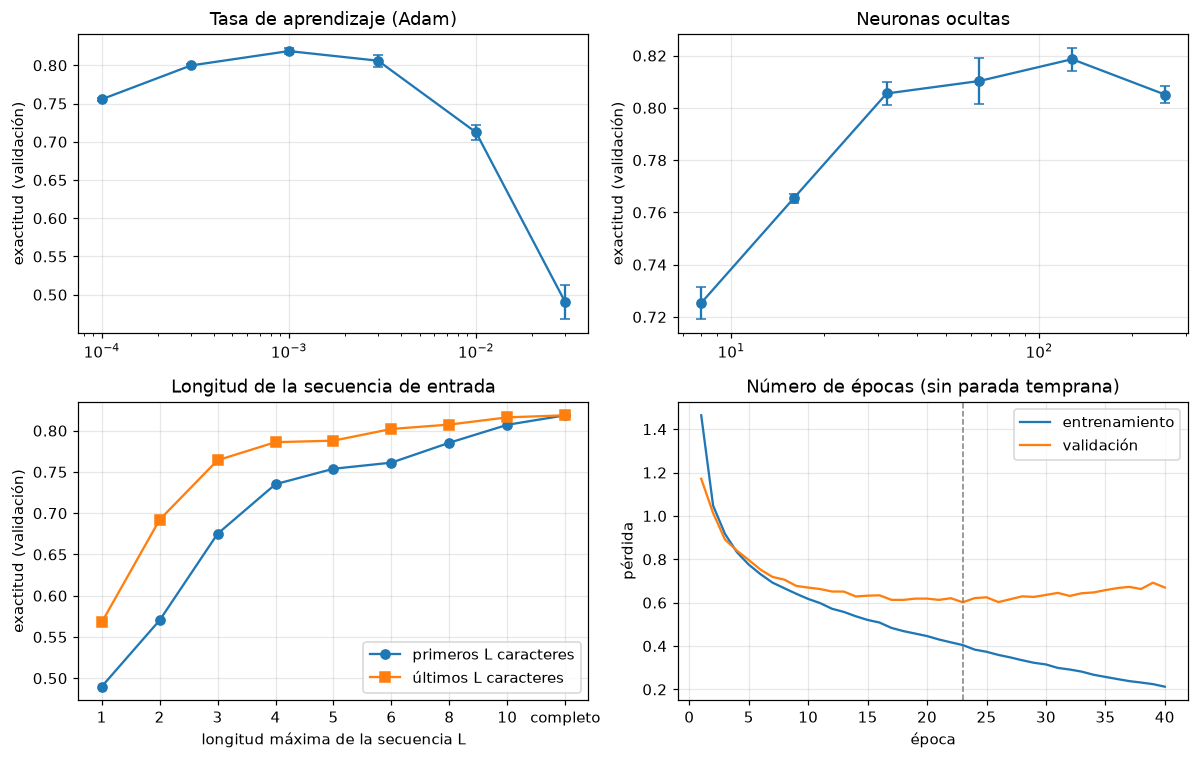

mínimo de la pérdida de validación en la época 23; exactitud de entrenamiento final 0.933 frente a validación 0.810


In [19]:
# número de épocas: una ejecución larga SIN parada temprana para ver la curva completa
_, info_largo = entrenar(nueva_rnn(H_FINAL), lr=LR_FINAL, epocas=40, paciencia=None)
hl = info_largo['hist']

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for df, a, titulo, log in [(bar_lr, ax[0, 0], 'Tasa de aprendizaje (Adam)', True),
                           (bar_h, ax[0, 1], 'Neuronas ocultas', True)]:
    a.errorbar(df.index, df['val_acc'], yerr=df['std'], marker='o', capsize=3)
    a.set_xscale('log' if log else 'linear'); a.set_title(titulo); a.set_ylabel('exactitud (validación)')
x = np.arange(len(tabla_long))
ax[1, 0].plot(x, tabla_long['primeros L (acc)'], marker='o', label='primeros L caracteres')
ax[1, 0].plot(x, tabla_long['últimos L (acc)'], marker='s', label='últimos L caracteres')
ax[1, 0].set_xticks(x, tabla_long.index); ax[1, 0].set_xlabel('longitud máxima de la secuencia L')
ax[1, 0].set_title('Longitud de la secuencia de entrada'); ax[1, 0].set_ylabel('exactitud (validación)'); ax[1, 0].legend()
ep = np.arange(1, len(hl['val_loss']) + 1)
ax[1, 1].plot(ep, hl['train_loss'], label='entrenamiento'); ax[1, 1].plot(ep, hl['val_loss'], label='validación')
ax[1, 1].axvline(info_largo['mejor_epoca'], color='gray', ls='--', lw=1)
ax[1, 1].set_title('Número de épocas (sin parada temprana)'); ax[1, 1].set_xlabel('época'); ax[1, 1].set_ylabel('pérdida')
ax[1, 1].legend()
plt.tight_layout(); plt.show()
print(f"mínimo de la pérdida de validación en la época {info_largo['mejor_epoca']}; "
      f"exactitud de entrenamiento final {hl['train_acc'][-1]:.3f} frente a validación {hl['val_acc'][-1]:.3f}")

**Tasa de aprendizaje.** La mejor es **0,001** (81,9 % en validación). Con 0,0001 y 0,0003 la red aprende demasiado despacio: la mejor época es la 40, la última, así que harían falta más épocas. Con 0,01 o más el entrenamiento es inestable: la pérdida de validación toca fondo en la época 2–4 y luego empeora (con 0,03 la exactitud cae al 49 %, casi el clasificador trivial).

**Neuronas ocultas.** La exactitud sube de 72,5 % (8 neuronas) a **81,9 % (128)** y baja con 256 (80,5 %). Con pocas neuronas el estado oculto no puede resumir el nombre (falta capacidad); con muchas la red memoriza antes (la mejor época llega antes: 18 frente a 40) y generaliza algo peor. Las diferencias entre 32 y 256 son de ±1 punto, del orden de la variación entre semillas.

**Longitud de la secuencia de entrada.** Es el resultado más revelador. Si la red solo ve los **últimos** L caracteres del nombre, con 3 ya acierta el 76,4 % y con 6 el 80,2 %, casi lo mismo que con el nombre completo (81,9 %). Con los **primeros** L caracteres necesita 10 para llegar al 80,7 %, y con 3 se queda en el 67,5 %. **La información sobre el idioma está sobre todo en el final del apellido**: «-ov», «-ski», «-ez», «-ini», «-escu», «-moto»… Además, a una RNN le resulta más fácil aprovechar el final, porque es lo último que entra en el estado oculto (lo del principio tiene que «sobrevivir» a muchas actualizaciones).

**Número de épocas.** Sin parada temprana, la pérdida de validación mínima está en la época **23** y después sube, mientras la de entrenamiento sigue bajando: en la época 40 la red acierta el 93,3 % en entrenamiento y el 81,0 % en validación. Es **sobreajuste**: la red empieza a memorizar nombres concretos. Por eso conviene la parada temprana.

La configuración elegida en validación coincide con la de partida: **h = 128 y tasa 0,001**, así que el modelo final es el D.

In [20]:
modelo_final, info_final = entrenar(nueva_rnn(H_FINAL), lr=LR_FINAL)
res_final, pred_final = metricas(modelo_final, X_ascii, idx_test)
print(f"Configuración final: h={H_FINAL}, lr={LR_FINAL}, mejor época {info_final['mejor_epoca']}")
tabla_pasos.loc['E · Configuración final'] = pd.Series(res_final | {'segundos/época': info_final['segundos'] / info_final['epocas']})
display(tabla_pasos)

Configuración final: h=128, lr=0.001, mejor época 23


,accuracy,f1_weighted,f1_macro,segundos/época
A · Base (nombre a nombre),0.8043,0.7959,0.5752,3.2674
B · Lotes empaquetados,0.7996,0.7883,0.5581,0.3969
C · + unicodeToAscii,0.8050,0.7951,0.5643,0.3969
"D · + Adam, media, parada temprana",0.8101,0.8014,0.5783,0.3740
E · Configuración final,0.8101,0.8014,0.5783,0.3797


# 3. Análisis de la matriz de confusión

Matriz del modelo final sobre el test, normalizada por filas: la celda (fila *i*, columna *j*) es la fracción de nombres del idioma *i* que la red asigna al idioma *j*. La diagonal es el **recall** (sensibilidad) de cada clase.

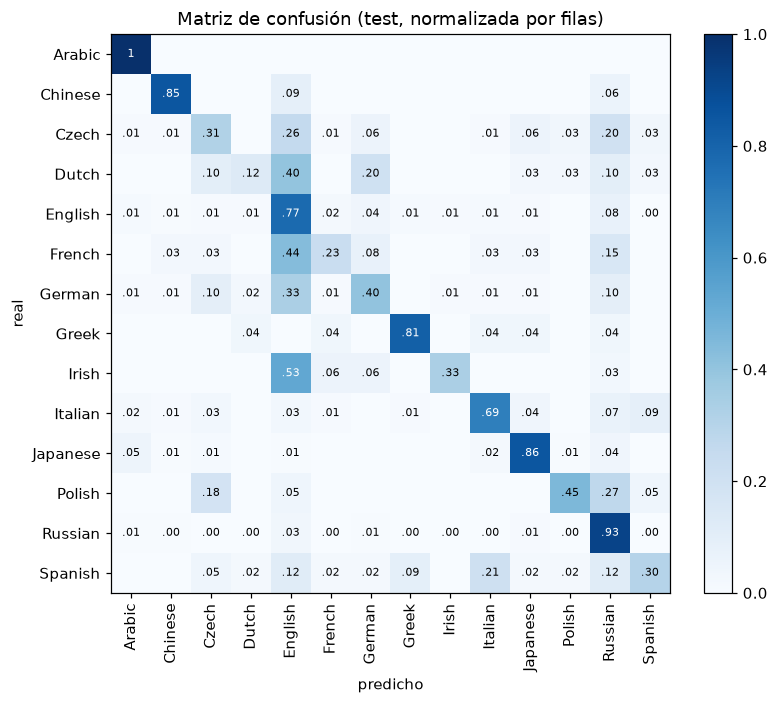

,precision,recall,f1-score,support
Dutch,0.3125,0.1250,0.1786,40
French,0.3103,0.2308,0.2647,39
Spanish,0.4194,0.3023,0.3514,43
Czech,0.4091,0.3140,0.3553,86
Irish,0.6000,0.3333,0.4286,36
German,0.5000,0.4048,0.4474,126
Polish,0.5882,0.4545,0.5128,22
Greek,0.5641,0.8148,0.6667,27
Italian,0.7143,0.6931,0.7035,101
Chinese,0.6591,0.8529,0.7436,34


In [21]:
y_test = y_todos[idx_test]
cm = sklearn.metrics.confusion_matrix(y_test, pred_final, labels=range(len(clases)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(len(clases)):
    for j in range(len(clases)):
        if cm[i, j]:
            ax.text(j, i, f'{cm_norm[i, j]:.2f}'.lstrip('0') if cm_norm[i, j] < 1 else '1',
                    ha='center', va='center', fontsize=7, color='white' if cm_norm[i, j] > 0.5 else 'black')
ax.set_xticks(range(len(clases)), clases, rotation=90); ax.set_yticks(range(len(clases)), clases)
ax.set_xlabel('predicho'); ax.set_ylabel('real'); ax.grid(False)
fig.colorbar(im, fraction=0.046); plt.title('Matriz de confusión (test, normalizada por filas)')
plt.tight_layout(); plt.show()

rep = sklearn.metrics.classification_report(y_test, pred_final, target_names=clases, output_dict=True, zero_division=0)
informe = pd.DataFrame({c: rep[c] for c in clases}).T
informe['support'] = informe['support'].astype(int)
display(informe.sort_values('f1-score'))

In [22]:
pares = [(clases[i], clases[j], cm[i, j], cm[i, j] / cm[i].sum())
         for i in range(len(clases)) for j in range(len(clases)) if i != j and cm[i, j] > 0]
top_conf = pd.DataFrame(pares, columns=['real', 'predicho', 'n', '% de la clase real']) \
    .sort_values('n', ascending=False).head(12).reset_index(drop=True)
display(top_conf)

nombres_test = np.array(alldata.data)[idx_test]
for real, predicho in top_conf[['real', 'predicho']].values[:6]:
    mal = nombres_test[(y_test == clases.index(real)) & (pred_final == clases.index(predicho))]
    print(f'{real:>8} -> {predicho:<8}: {", ".join(mal[:8])}')

,real,predicho,n,% de la clase real
0,Russian,English,47,0.0336
1,English,Russian,45,0.0780
2,German,English,42,0.3333
3,English,German,23,0.0399
4,Czech,English,22,0.2558
5,Irish,English,19,0.5278
6,French,English,17,0.4359
7,Czech,Russian,17,0.1977
8,Dutch,English,16,0.4000
9,Russian,Japanese,14,0.0100


 Russian -> English : Dehant, Talroze, Hurdey, Ents, Islon, Jelnin, Luppol, Horvat
 English -> Russian : Sheridan, Fairbrother, Vallance, Daugherty, Palfreyman, Marks, Shakespeare, Llewellyn
  German -> English : Tiedeman, Wirnhier, West, Waldfogel, Dürr, Brandt, Amsel, Fried
 English -> German  : Gallacher, Stringer, Crowther, Warner, Begum, Amner, Livingstone, Banner
   Czech -> English : Hrdy, Lind, Hynna, Siegl, Olbrich, Oborny, Hartl, Cerney
   Irish -> English : Cathasach, Flynn, Flann, Aodh, Ruadh, Farrell, Power, Rinn


In [23]:
# ¿Cuánto influyen los duplicados y los nombres con varios idiomas?
nombres_train = set(np.array(alldata.data)[idx_train])
visto = np.array([n in nombres_train for n in nombres_test])
idiomas_de = collections.defaultdict(set)
for n, l in zip(alldata.data, alldata.labels):
    idiomas_de[n].add(l)
ambiguo = np.array([len(idiomas_de[n]) > 1 for n in nombres_test])
acierto = pred_final == y_test

print(f'Nombres del test que también están en entrenamiento: {visto.sum()} ({visto.mean():.1%})')
print(f'  exactitud en los ya vistos: {acierto[visto].mean():.3f} | en los nuevos: {acierto[~visto].mean():.3f}')
print(f'Nombres del test que aparecen en más de un idioma: {ambiguo.sum()} ({ambiguo.mean():.1%}); '
      f'exactitud en ellos: {acierto[ambiguo].mean():.3f}')
por_clase = pd.DataFrame({'clase': np.array(clases)[y_test], 'visto': visto}).groupby('clase')['visto'].mean()
print('Fracción del test ya vista en entrenamiento, por clase:')
print(por_clase.sort_values(ascending=False).round(2).to_string())
ejemplos = [n for n in sorted(idiomas_de) if len(idiomas_de[n]) >= 3][:8]
print('Ejemplos de nombres en 3 o más idiomas:', {n: sorted(idiomas_de[n]) for n in ejemplos})

Nombres del test que también están en entrenamiento: 402 (13.6%)
  exactitud en los ya vistos: 0.836 | en los nuevos: 0.806
Nombres del test que aparecen en más de un idioma: 114 (3.9%); exactitud en ellos: 0.377
Fracción del test ya vista en entrenamiento, por clase:
clase
Arabic      1.00
Irish       0.28
Spanish     0.23
Chinese     0.18
Dutch       0.18
German      0.15
Polish      0.14
Czech       0.10
English     0.05
French      0.05
Italian     0.05
Greek       0.04
Russian     0.01
Japanese    0.01
Ejemplos de nombres en 3 o más idiomas: {'Abel': ['English', 'French', 'German', 'Russian', 'Spanish'], 'Adam': ['English', 'French', 'German', 'Irish', 'Russian'], 'Adler': ['English', 'German', 'Russian'], 'Albert': ['English', 'French', 'German', 'Russian', 'Spanish'], 'Berger': ['English', 'French', 'German'], 'Bernard': ['English', 'French', 'Polish'], 'Costa': ['English', 'Italian', 'Spanish'], 'David': ['English', 'French', 'Russian']}


### Qué países se confunden y por qué

**1. Casi todo lo que se falla acaba en English.** Los mayores porcentajes fuera de la diagonal están en la columna English: **Irish → English 53 %, French → English 44 %, Dutch → English 40 %, German → English 33 %, Czech → English 26 %**. Las causas:

* **Desequilibrio de clases**: English es la segunda clase más grande (18,6 %). Ante la duda, la red se inclina por la clase grande, que es lo que minimiza la pérdida media. Las clases con peor recall son justo las pequeñas: Dutch (12,5 %), French (23 %), Spanish (30 %), Czech (31 %) e Irish (33 %).
* **El archivo English es, en realidad, de apellidos presentes en Inglaterra**, muchos de origen alemán, francés, irlandés u holandés. Los nombres que la red asigna mal lo muestran: «Brandt», «Fried» o «West» (German → English), y «Flynn», «Farrell» o «Power» (Irish → English) son apellidos perfectamente anglosajones a la vista.
* **Nombres compartidos**: 114 nombres del test (3,9 %) aparecen en más de un idioma («Abel» en 5, «Adam» en 5, «Albert» en 5, «Costa» en 3…). Para ellos la tarea es imposible por construcción: la exactitud es del 37,7 %.

**2. Familias lingüísticas.** Czech → Russian (20 %), German → Czech, Polish → Russian: los idiomas eslavos comparten sufijos (-ov, -ek, -sky/-ski) y los germánicos (German, Dutch, English) comparten raíces y grafías. Dutch es la clase peor reconocida: comparte muchísimo con German y English y tiene pocos ejemplos.

**3. Los mejores resultados no son siempre mérito de la red.**

* **Arabic tiene un recall del 100 %**, pero el 100 % de sus nombres de test **ya estaban en el entrenamiento** (108 nombres distintos repetidos 2000 veces): es memorización, no generalización.
* **Russian** (92,5 %), **Japanese** (85,5 %) y **Chinese** (85,3 %) sí son méritos reales: casi ningún nombre de test se había visto, pero sus grafías son muy distintivas (vocales alternadas en japonés, sílabas cortas en chino, sufijos en ruso).
* En total, los nombres de test vistos en entrenamiento se aciertan un 83,6 % y los nuevos un 80,6 %. La exactitud de la tabla está ligeramente inflada por los duplicados.

In [24]:
# Desequilibrio: pérdida ponderada por clase (peso inversamente proporcional a la frecuencia)
frec = np.bincount(y_todos[idx_train], minlength=len(clases))
pesos = len(idx_train) / (len(clases) * frec)
modelo_pond, info_pond = entrenar(nueva_rnn(H_FINAL), lr=LR_FINAL, pesos_clase=pesos)
res_pond, pred_pond = metricas(modelo_pond, X_ascii, idx_test)
rec = lambda p: sklearn.metrics.recall_score(y_test, p, average=None, labels=range(len(clases)))
comp_pond = pd.DataFrame({'recall sin pesos': rec(pred_final), 'recall con pesos': rec(pred_pond)}, index=clases)
display(pd.DataFrame({'sin pesos': res_final, 'con pesos de clase': res_pond}).T)
display(comp_pond.sort_values('recall sin pesos').round(3))

,loss,accuracy,f1_weighted,f1_macro
sin pesos,0.6064,0.8101,0.8014,0.5783
con pesos de clase,0.8969,0.7165,0.7380,0.5320


,recall sin pesos,recall con pesos
Dutch,0.125,0.225
French,0.231,0.513
Spanish,0.302,0.512
Czech,0.314,0.512
Irish,0.333,0.472
German,0.405,0.500
Polish,0.455,0.455
Italian,0.693,0.663
English,0.775,0.475
Greek,0.815,0.778


**Pesos de clase: una mejora con un coste.** Dar más peso a las clases pequeñas en la pérdida sube mucho su recall (French 23 → 51 %, Spanish 30 → 51 %, Czech 31 → 51 %), pero a costa de las grandes (English 77 → 48 %, Russian 93 → 82 %). La exactitud baja al 71,7 % y, en este caso, **incluso el F1 macro baja** (0,578 → 0,532), porque la precisión de las clases pequeñas cae más de lo que sube su recall: la red empieza a asignarles muchos nombres ingleses o rusos. Si el objetivo fuera detectar idiomas minoritarios podría compensar; para la métrica de la práctica (exactitud y F1 ponderado) no conviene, así que el modelo final no usa pesos.

# 4. Comparación con una red feedforward (FNN)

Una FNN no tiene memoria: necesita una **entrada de tamaño fijo**. Se prueban tres formas razonables de convertir el nombre en un vector, todas con **la misma capa oculta (128 neuronas, tanh)**, la misma salida (14), el mismo optimizador, la misma tasa, la misma parada temprana y los mismos datos:

* **FNN posicional (alineada a la izquierda)**: los one-hot de los 20 primeros caracteres concatenados (rellenando con ceros) → vector de $20\times58 = 1160$. Conserva el orden, pero cada posición tiene **sus propios pesos**: lo aprendido sobre una «v» en la posición 6 no sirve para una «v» en la posición 8.
* **FNN posicional (alineada a la derecha)**: igual, pero el nombre se coloca al **final** del vector, de modo que el último carácter siempre ocupa la misma posición. Los sufijos quedan alineados.
* **FNN bolsa de caracteres**: la suma de los one-hot (cuántas veces aparece cada carácter), vector de 58. Pierde completamente el orden.

La RNN, en cambio, **comparte los mismos pesos en todas las posiciones** y lee el orden de forma natural.

In [25]:
LONG_FNN = 20

class FNN(nn.Module):
    def __init__(self, n_entrada, n_oculta, n_clases, representacion='izquierda'):
        super().__init__()
        self.n_entrada, self.representacion = n_entrada, representacion
        d = n_entrada if representacion == 'bolsa' else LONG_FNN * n_entrada
        self.red = nn.Sequential(nn.Linear(d, n_oculta), nn.Tanh(), nn.Linear(n_oculta, n_clases))

    def forward(self, x, longitudes):
        oh = F.one_hot(x, self.n_entrada + 1)[..., :self.n_entrada].float()     # (B, T, 58), relleno a 0
        if self.representacion == 'bolsa':
            z = oh.sum(dim=1)
        else:
            B, T, n = oh.shape
            z = torch.zeros(B, LONG_FNN, n)
            if self.representacion == 'izquierda':
                z[:, :min(T, LONG_FNN)] = oh[:, :LONG_FNN]
            else:                                   # derecha: el último carácter siempre en la última posición
                for b in range(B):
                    L = min(int(longitudes[b]), LONG_FNN)
                    z[b, LONG_FNN - L:] = oh[b, int(longitudes[b]) - L:int(longitudes[b])]
            z = z.flatten(1)
        return self.red(z)


modelos_cmp = {
    'RNN (h=128)': lambda: CharRNNLotes(n_letters, 128, len(clases)),
    'FNN posicional izq. (h=128)': lambda: FNN(n_letters, 128, len(clases), 'izquierda'),
    'FNN posicional der. (h=128)': lambda: FNN(n_letters, 128, len(clases), 'derecha'),
    'FNN bolsa de caracteres (h=128)': lambda: FNN(n_letters, 128, len(clases), 'bolsa'),
}
filas = []
for nombre, crear in modelos_cmp.items():
    for s in (0, 1, 2):
        m, info = entrenar(crear, lr=LR_FINAL, semilla=s)
        r, _ = metricas(m, X_ascii, idx_test)
        filas.append({'modelo': nombre, 'semilla': s, 'parámetros': contar_parametros(m),
                      'test_acc': r['accuracy'], 'f1_macro': r['f1_macro'], 'val_acc': info['val_acc'],
                      'train_acc': info['hist']['train_acc'][info['mejor_epoca'] - 1],
                      'mejor_época': info['mejor_epoca'], 's/época': info['segundos'] / info['epocas']})
cmp_fnn = pd.DataFrame(filas).groupby('modelo', sort=False).agg(
    parámetros=('parámetros', 'first'), test_acc=('test_acc', 'mean'), test_acc_std=('test_acc', 'std'),
    f1_macro=('f1_macro', 'mean'), train_acc=('train_acc', 'mean'), mejor_época=('mejor_época', 'mean'),
    s_época=('s/época', 'mean'))
display(cmp_fnn)

,parámetros,test_acc,test_acc_std,f1_macro,train_acc,mejor_época,s_época
modelo,,,,,,,
RNN (h=128),25870,0.8138,0.0070,0.5801,0.8607,21.3333,0.3800
FNN posicional izq. (h=128),150414,0.7541,0.0042,0.4980,0.7918,14.6667,0.1880
FNN posicional der. (h=128),150414,0.7865,0.0012,0.5479,0.8259,7.6667,0.3204
FNN bolsa de caracteres (h=128),9358,0.7596,0.0045,0.4841,0.7894,39.6667,0.1401


**La RNN gana a las tres FNN** (81,4 % ± 0,7 frente a 78,7 %, 75,4 % y 76,0 %), y lo hace con **seis veces menos parámetros** que las FNN posicionales (25 870 frente a 150 414).

* **FNN posicional a la izquierda (75,4 %)**: la peor de las tres. Cada posición tiene sus propios pesos, así que lo aprendido sobre «-ov» en las posiciones 5–6 de «Ivanov» no sirve para «-ov» en las posiciones 8–9 de «Rachmaninov». Además, 150 000 parámetros con 14 000 nombres se sobreajustan antes (mejor época ≈ 15).
* **FNN posicional a la derecha (78,7 %)**: con solo alinear el final del nombre gana 3,2 puntos. Confirma el resultado de la longitud de secuencia: el final del nombre es lo informativo, y si siempre está en la misma posición, la FNN lo aprovecha.
* **FNN bolsa de caracteres (76,0 %)**: sin ningún orden ya acierta el 76 %. Qué letras aparecen (k, z, w, y, ñ…) dice mucho del idioma. El orden aporta los 5 puntos restantes.

**¿Funciona una RNN mucho mejor que una FNN en este problema?** Mejor sí, **mucho mejor no**: la ventaja es de unos 3 puntos sobre una FNN bien diseñada. Los nombres son cortos (mediana de 7 caracteres) y el idioma se decide en los últimos caracteres, así que no hacen falta dependencias largas, que es donde una RNN marca la diferencia. Su ventaja real es estructural: **comparte los pesos en todas las posiciones**, acepta cualquier longitud sin rellenar ni recortar y necesita muchos menos parámetros.

# 5. Conclusiones

1. **Codificación y funcionamiento.** Cada carácter es un one-hot de 58 posiciones y un nombre es una secuencia `(T, 1, 58)`. La RNN actualiza un estado oculto de 128 números con $\mathbf h_t=\tanh(\mathbf x_t\mathbf W_{xh}+\mathbf h_{t-1}\mathbf W_{hh}+\mathbf b)$ y clasifica con el **último** estado. Ese estado es un resumen de longitud fija de un nombre de longitud variable, y la secuencia de prefijos muestra cómo se va formando.
2. **Rendimiento.** El modelo base acierta el **80,4 %** (F1 ponderado 0,80, F1 macro 0,58) frente al 47,7 % del clasificador trivial. Las mejoras de código (lotes empaquetados, `unicodeToAscii`, etiquetas reproducibles) hacen el entrenamiento **unas 8 veces más rápido** sin perder exactitud. Las de metodología (validación, Adam, parada temprana) dan el **81,0 %** con una evaluación honesta.
3. **Hiperparámetros.** La tasa de aprendizaje es el más sensible (de 49 % a 82 % según su valor); el tamaño oculto tiene un óptimo en torno a 64–128; la parada temprana evita el sobreajuste que aparece tras unas 20 épocas. El experimento de longitud muestra que **los últimos 6 caracteres bastan para el 80 %**: el idioma está en el sufijo.
4. **Matriz de confusión.** Los errores van sobre todo hacia **English** (desequilibrio, apellidos anglicanizados, nombres compartidos entre idiomas) y dentro de las **familias lingüísticas** (eslavas, germánicas). El 100 % de Arabic es memorización de duplicados. Una parte del error es irreducible: el mismo nombre aparece con varias etiquetas.
5. **RNN frente a FNN.** La RNN es la mejor (81,4 % frente a 78,7 % de la mejor FNN) con 6 veces menos parámetros, pero la diferencia es moderada porque los nombres son cortos. La FNN depende de cómo se alinea la entrada (izquierda 75,4 %, derecha 78,7 %); la RNN no necesita esa decisión.

In [26]:
resultados = {
    'clases': clases,
    'conteo': {c: int(conteo[c]) for c in clases},
    'distintos': {c: int(unicos[c]) for c in clases},
    'pasos': {k: {m: float(v) for m, v in fila.items()} for k, fila in tabla_pasos.T.to_dict().items()},
    'lr': {str(k): [float(v['val_acc']), float(v['std'])] for k, v in bar_lr.iterrows()},
    'h': {str(k): [float(v['val_acc']), float(v['std'])] for k, v in bar_h.iterrows()},
    'longitud': {k: [float(a), float(b)] for k, a, b in zip(tabla_long.index, tabla_long.iloc[:, 0], tabla_long.iloc[:, 1])},
    'epocas': {'train_loss': hl['train_loss'], 'val_loss': hl['val_loss'], 'mejor': info_largo['mejor_epoca']},
    'final': {'lr': LR_FINAL, 'h': H_FINAL} | {k: float(v) for k, v in res_final.items()},
    'cm': cm.tolist(),
    'top_conf': top_conf.to_dict(orient='records'),
    'recall': {c: [float(a), float(b)] for c, a, b in zip(clases, comp_pond.iloc[:, 0], comp_pond.iloc[:, 1])},
    'ponderado': {k: float(v) for k, v in res_pond.items()},
    'duplicados': {'vistos': float(visto.mean()), 'acc_vistos': float(acierto[visto].mean()),
                   'acc_nuevos': float(acierto[~visto].mean()), 'ambiguos': float(ambiguo.mean()),
                   'acc_ambiguos': float(acierto[ambiguo].mean())},
    'fnn': {k: {c: float(v) for c, v in fila.items()} for k, fila in cmp_fnn.T.to_dict().items()},
}
with open(LAB_DIR / 'resultados_lab2_nombres.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=float)
print('Resultados guardados en resultados_lab2_nombres.json')

Resultados guardados en resultados_lab2_nombres.json
